In [2]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
A_file="..."
L_file = "/content/drive/MyDrive/DATA 102 Final Project/EDA/concentrations.csv"
air_quality = pd.read_csv(L_file)
air_quality.head()

,year,date,statefips,countyfips,pm25_max_pred,pm25_med_pred,pm25_mean_pred,pm25_pop_pred
0,2001,01JAN2001,6,6001,56.708484,52.434557,52.751494,52.942986
1,2001,01JAN2001,6,6003,12.663324,12.663324,12.663324,12.663324
2,2001,01JAN2001,6,6005,25.662103,21.031934,21.176171,21.894553
3,2001,01JAN2001,6,6007,26.702092,25.527019,25.356636,25.364373
4,2001,01JAN2001,6,6009,24.662062,18.489823,19.373269,20.626233


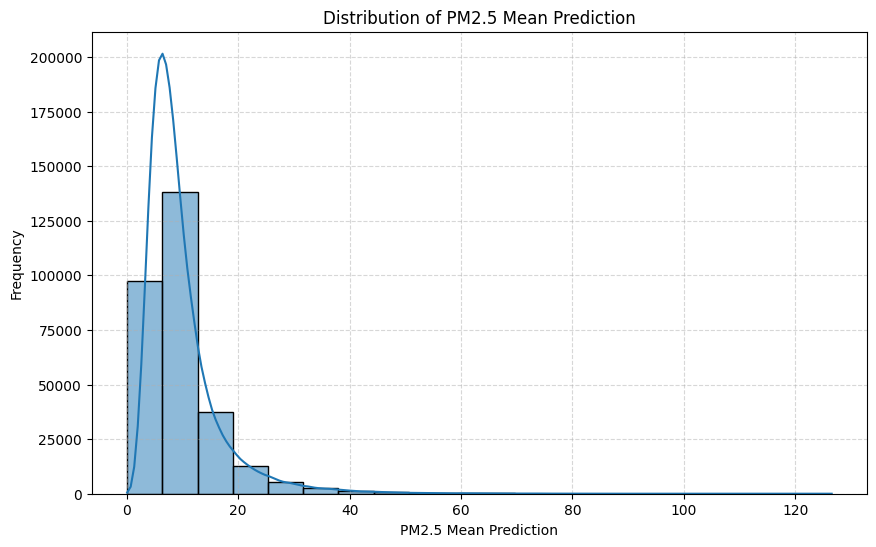

In [36]:
plt.figure(figsize=(10, 6))
sns.histplot(data=air_quality, x='pm25_mean_pred', bins=20, kde=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('PM2.5 Mean Prediction')
plt.ylabel('Frequency')
plt.title('Distribution of PM2.5 Mean Prediction')
plt.show()

In the above plot, we visualize the mean PM 2.5 values across the state of California over the period 2001-2014. The plot reveals that the distribution is skewed to the right significantly, and there are several outliers in terms of large (>=30) values. In order to assess trends in the mean PM 2.5 levels across the years, we decided to look at the data for Los Angeles County in particular.

In [29]:
air_quality['pm25_mean_pred'].describe()

,pm25_mean_pred
count,296554.000000
mean,9.826575
std,6.895152
min,0.069821
25%,5.670295
50%,8.039741
75%,11.632520
max,126.537389


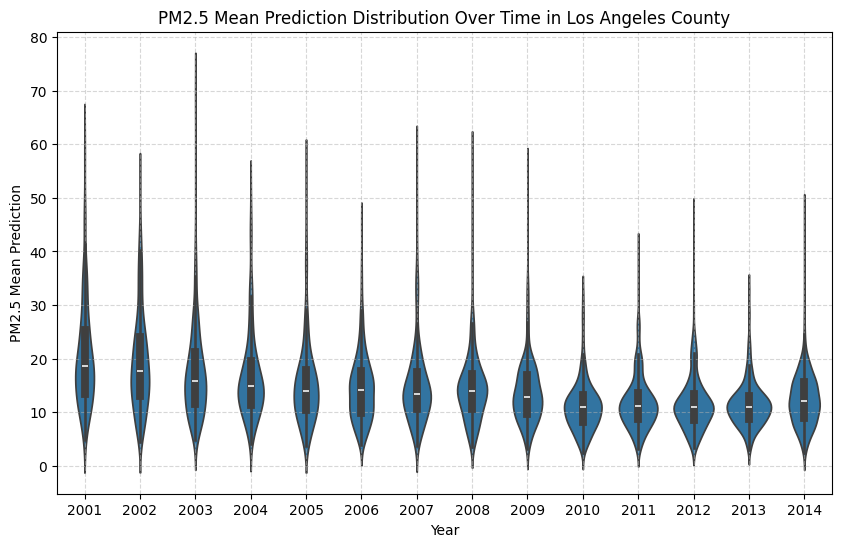

In [35]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=air_quality[air_quality['countyfips'] == 6037], x='year', y='pm25_mean_pred')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('Year')
plt.ylabel('PM2.5 Mean Prediction')
plt.title('PM2.5 Mean Prediction Distribution Over Time in Los Angeles County')
plt.show()

Here, we are plotting the distribution of the mean Particulate Matter (PM) 2.5 levels in Los Angeles County from 2001 to 2014 as a violin plot.
Looking at the data from L.A. county, we can see that there is a relative downward trend in the mean PM 2.5 values across the years. Furthermore, there is also a decreasing trend in the highest PM 2.5 values (the upper outliers). This might be attributed to more environmentally conscious laws in California in the late 2000s and early 2010s, and is a factor that we would like to consider as we move forward in this project.

In [5]:
air_quality.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296554 entries, 0 to 296553
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            296554 non-null  int64  
 1   date            296554 non-null  object 
 2   statefips       296554 non-null  int64  
 3   countyfips      296554 non-null  int64  
 4   pm25_max_pred   296554 non-null  float64
 5   pm25_med_pred   296554 non-null  float64
 6   pm25_mean_pred  296554 non-null  float64
 7   pm25_pop_pred   296554 non-null  float64
dtypes: float64(4), int64(3), object(1)
memory usage: 18.1+ MB


In [8]:
air_quality['countyfips'].unique()

array([6001, 6003, 6005, 6007, 6009, 6011, 6013, 6015, 6017, 6019, 6021,
       6023, 6025, 6027, 6029, 6031, 6033, 6035, 6037, 6039, 6041, 6043,
       6045, 6047, 6049, 6051, 6053, 6055, 6057, 6059, 6061, 6063, 6065,
       6067, 6069, 6071, 6073, 6075, 6077, 6079, 6081, 6083, 6085, 6087,
       6089, 6091, 6093, 6095, 6097, 6099, 6101, 6103, 6105, 6107, 6109,
       6111, 6113, 6115])

TODO: map name of counties with fips

In [38]:
dict = {
    6037: 'Los Angeles',
    6059: 'Orange County',
    6071: 'San Bernardino',
    6065: 'Riverside County',
    6073: 'San Diego'
}

In [10]:
county_fips =[6037, 6059, 6071, 6065, 6073]

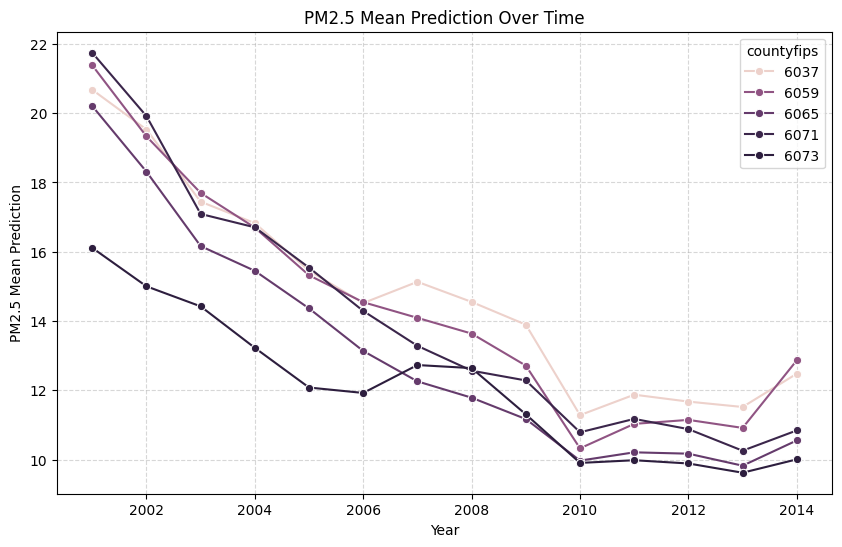

In [22]:
plt.figure(figsize=(10, 6))
top_5_counties = air_quality[air_quality['countyfips'].isin(county_fips)]
df = top_5_counties.groupby(['year', 'countyfips'])['pm25_mean_pred'].mean().reset_index()
# type(df)
sns.lineplot(data=df, x='year', y='pm25_mean_pred', hue='countyfips', marker='o')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('Year')
plt.ylabel('PM2.5 Mean Prediction')
plt.title('PM2.5 Mean Prediction Over Time')
plt.show()

Here, we are plotting the mean PM 2.5 levels across the five most populated counties in California from 2001 to 2014. Each line represents the average PM 2.5 value across time for a given county.
This plot shows a significant downward trend in the mean PM 2.5 values, indicating that air quality has improved a lot by this metric from 2001 to 2014. Specifically, we observe a big dip in 2010, and find that trend interesting to explore further.
We also notice that these trends seem much more rapid than the plot above, even though this plot also describes L.A. county, and we find that to be an interesting observation that deserves more scrutiny.

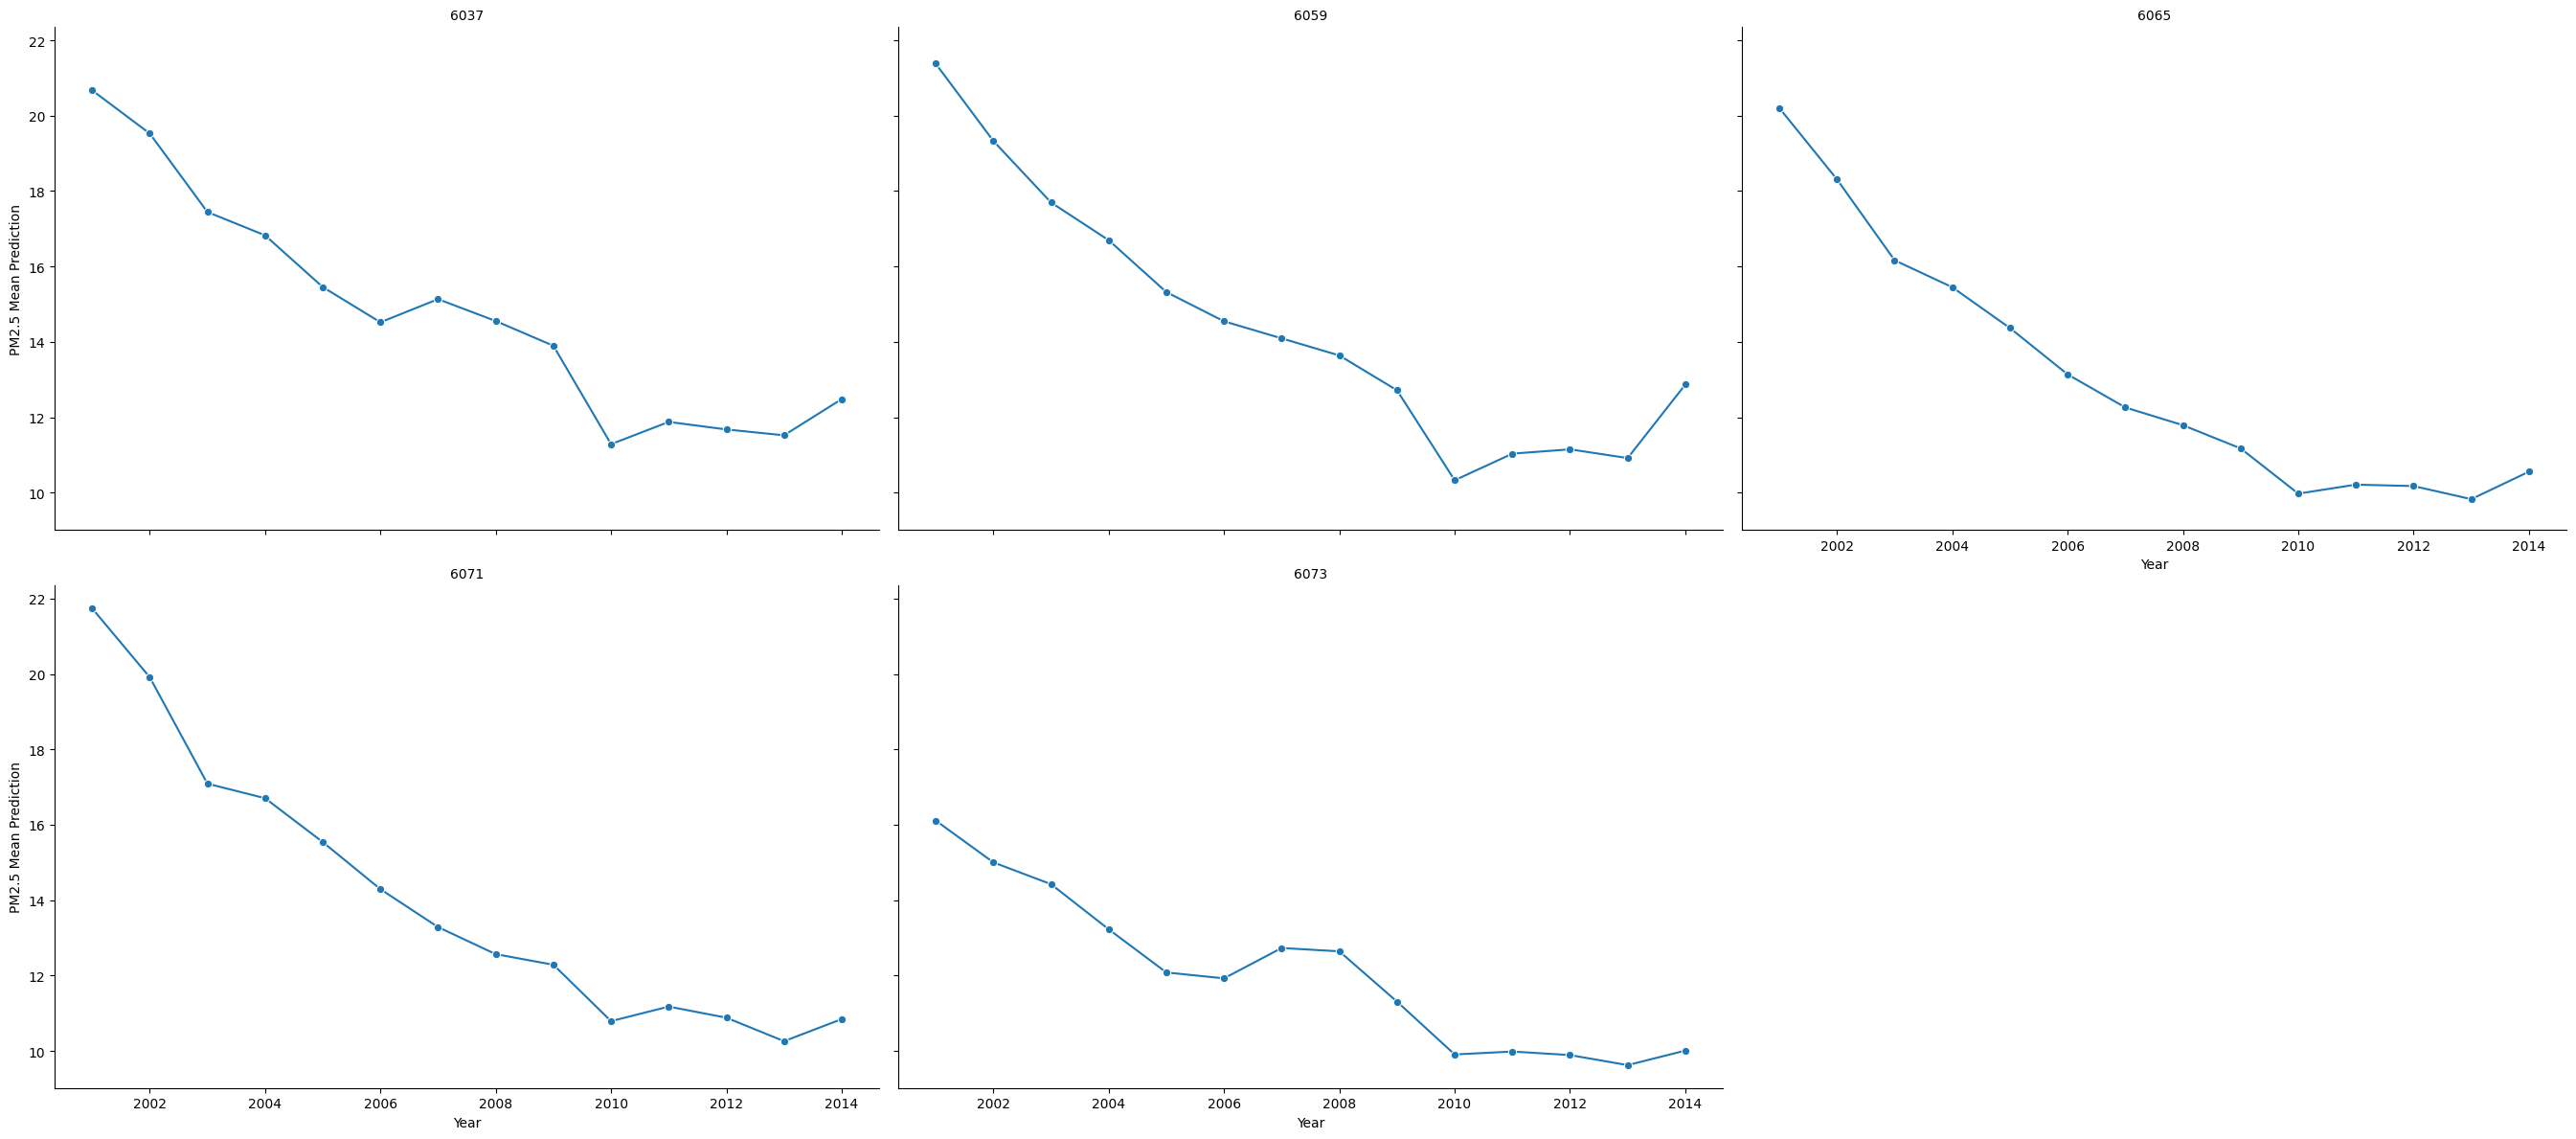

In [24]:

g = sns.FacetGrid(df, col='countyfips', col_wrap=3, height=6, aspect=1.5)
g.map(sns.lineplot, 'year', 'pm25_mean_pred', marker='o')

g.set_axis_labels("Year", "PM2.5 Mean Prediction")
g.set_titles("{col_name}")
g.tight_layout()
# plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Here, we plot the average PM 2.5 trends from 2001 to 2014 individually for the five most populated counties in California. The trends observed are the same as the previous plot, but this visualization provides some more clarity on a county-by-county basis. We also notice that among the five selected counties, the least change across 14 years happens in San Diego County, while the most change occurs in San Bernardino County. However, the consistently best air quality is observed in San Diego County, which has low PM 2.5 levels overall compared to the other counties.